## **```CHIRAG VYAS-```** 
## **```AIML PROJECT 03 AI BASED Customer Behaviour Prediction Platform```**
## **```EXPLORATORY DATA ANALYSIS```**
- **Name:** VANTARA RETAIL SOLUTIONS
- **AIML:** Machine Learning & Deep Learning System for Churn, Lifetime Value, and Purchase Behavior Prediction 
- **Analytical system** - to produce
  - churn risk scores
  - customer lifetime value estimates
  - next-purchase probability
  - product recommendations
  - customer segments
  - interactiv dashboards
- **file_name:** 01_eda.ipynb

## **INDEX**


|`Sr No.`|`Section ID`| `Description`|
|--|---|-----|
|||**A. EDA For Raw Dataset:**|
|**1**|**Step 1**|[Loading Dataset](#Step-1-Dataset-loading:)|
|**2**|**Step 2**|[Validate Dataset](#Step-2-Dataset-Validation:)|
|**3**|**Step 3**|[Data Analysis:](#Step-3-Data-Analysis:)|
|**4**|**Step 4**|[Pre Cleaning Exploratory Data Analysis (EDA)-Descriptive Statistics:](#Step-4-Pre-Cleaning-Exploratory-Data-Analysis-(EDA)-Descriptive-Statistics:)|
|**5**|**Step 5**|[Pre Cleaning Exploratory Data Analysis (EDA)-Transaction Value Analysis:](#Step-5-Pre-Cleaning-Exploratory-Data-Analysis-(EDA)-Transaction-Value-Analysis:)|
|**6**|**Step 6**|[Pre Cleaning Exploratory Data Analysis (EDA)-Categorical Data Analysis:](#Step-6-Pre-Cleaning-Exploratory-Data-Analysis-(EDA)-Categorical-Data-Analysis:)|
|**7**|**Step 7**|[Quantity Distribution:](#Step-7-Quantity-Distribution:)|
|**8**|**Step 8**|[Price Distribution:](#Step-8-Price-Distribution:)|
|**9**|**Step 9**|[Transaction Value Distribution:](#Step-9-Transaction-Value-Distribution:)|
|**10**|**Step 10**|[Vantara Dataset cleaning - pipeline:](#Step-10-Vantara-Dataset-cleaning---pipeline:)|
|**11**|**Step 11**|[Dataquality Report](#Step-11-Vantara-Dataset-Validation:)|
|**12**|**Step 12**|[Step 12 Saving cleaned Dataframe:](#Step-12-Saving-cleaned-Dataframe:)|
|||**B. EDA For Feature Engineering Churndataset:**|
|**1**|**Step 1**|[Dataset loading:](#Step-1.-Dataset-loading:)|
|**2**|**Step 2**|[Churn Target Distribution:](#Step-2.-Churn-Target-Distribution:)|
|**3**|**Step 3**|[analyze_numerical_features:](#Step-3.-analyze_numerical_features:)|
|**4**|**Step 4**|[Feature Distribution & Outlier Analysis:](#Step-4.-Feature-Distribution-&-Outlier-Analysis:)|
|**5**|**Step 5**|[Compare Features by Churn:](#Step-5.-Compare-Features-by-Churn:)|
|**6**|**Step 6**|[Correlation with Churn:](#Step-6.-Correlation-with-Churn:)|
|**7**|**Step 7**|[Feature to Feature Correlation:](#Step-7.-Feature-to-Feature-Correlation:)|
|**8**|**Step 8**|[VIF Analysis:](#Step-8.-VIF-Analysis:)|
|**9**|**Step 9**|[Important Features & Initial Churn Hypotheses:](#Step-9.-Important-Features-&-Initial-Churn-Hypotheses:)|




















In [3]:
############################### DATA WRANGLING / PREPROCESSING LIBRARY  #######################################
#-----------Importing Library for data mathematics -----------
import numpy as np
import pandas as pd
import math
import ast

#------------Importing Library for visulization-----------------
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

#-----------Import warning module to handle future warnning -------
import warnings
warnings.filterwarnings('ignore',category=FutureWarning)

#------------Import precosssing model--------------
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import LabelEncoder

########################################## MACHINE LEARNING MODEL ##############################################

#----------Import Machine Learning Libraries------------
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import RandomizedSearchCV

#----------Importing LinearModel------------------------
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet
from sklearn.svm import SVR
from sklearn.naive_bayes import GaussianNB


#----------Importing Ensembled Model - regression---------------------
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor

#----------Importing Ensembled Model - classification---------------------
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import  GradientBoostingClassifier
from xgboost import XGBClassifier

#----------Importing Library for evaluation of models----
from sklearn.metrics import root_mean_squared_error,mean_absolute_error,r2_score,mean_squared_error
from sklearn.metrics import confusion_matrix, f1_score, recall_score, accuracy_score, precision_score, balanced_accuracy_score
from sklearn.metrics import roc_curve,roc_auc_score


####################################### DEEP LEARNING MODEL ######################################################

#----------Importing Deeplearning Model Libraries -----------
from tensorflow.keras.layers import Input, Dense, Conv2D, LSTM, Dropout, Flatten
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.optimizers import Adam,SGD
from tensorflow.keras.callbacks import EarlyStopping

########################################### IMPORTING FOR DASHBOARD ##############################################
import streamlit as st
import sys
from pathlib import Path

##################################################################################################################

#import yfinance as yf
#from pandas_datareader import data as web
from datetime import datetime, timedelta
import re
#import pandas_market_calendars as mcal

In [4]:
project_root = Path.cwd().parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

**[GO TO INDEX](#INDEX)**

## **``Step 1 Dataset loading:``**

In [40]:
import importlib
import src.data.ingest as ingest
importlib.reload(ingest)
from src.data.ingest import load_online_retail_ii

In [41]:
df = load_online_retail_ii()
df.head()

Dataset already exists: E:\10. Internmo Projects\AIML_internmo_Project3_Vantara\2.AIML_Project3_Vantara_retail_solution\customer-behaviour-prediction\data\raw\online_retail_II.xlsx


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


**[GO TO INDEX](#INDEX)**

## **``Step 2 Dataset Validation:``**

In [5]:
import importlib
import src.data.validate as validate
importlib.reload(validate)
from src.data.validate import validate_dataset
from src.data.validate import display_validation_report

In [6]:
validation_report = validate_dataset(df)
display_validation_report(validation_report)

VANTARA CUSTOMER BEHAVIOR PLATFORM
DATASET VALIDATION REPORT

DATASET OVERVIEW
----------------------------------------------------------------------
Rows                               : 1,067,371
Columns                            : 8
Unique Customers                   : 5,942
Unique Invoices                    : 53,628
Unique Products                    : 5,305
Countries                          : 43

DATE RANGE
----------------------------------------------------------------------
Start Date                         : 2009-12-01
End Date                           : 2011-12-09
Invalid Dates                      : 0

DATA QUALITY
----------------------------------------------------------------------
Missing Customer ID                : 243,007
Missing Customer ID (%)            : 22.77%
Duplicate Rows                     : 34,335
Negative Quantity                  : 22,950
Zero Quantity                      : 0
Zero Price                         : 6,202
Negative Price                  

**[GO TO INDEX](#INDEX)**

## **``Step 3 Data Analysis:``**

In [7]:
import importlib
import src.data.analysis as analysis
importlib.reload(analysis)
from src.data.analysis import (
    analyze_structure,
    analyze_missing_values,
    analyze_duplicates,
    analyze_data_quality,
    stockcode_data_quality,
    display_analysis
)

**structure analysis**

In [8]:
structure_analysis = analyze_structure(df)
display_analysis("DATASET STRUCTURE ANALYSIS", structure_analysis)


                      DATASET STRUCTURE ANALYSIS                      
Rows                               : 1,067,371
Columns                            : 8
Column Names                       : ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Data Types
----------
    Invoice                            : object
    Stockcode                          : object
    Description                        : object
    Quantity                           : int64
    Invoicedate                        : datetime64[us]
    Price                              : float64
    Customer Id                        : float64
    Country                            : str
Start Date                         : 2009-12-01 07:45:00
End Date                           : 2011-12-09 12:50:00
Invalid Dates                      : 0


**missing analysis**

In [9]:
missing_analysis = analyze_missing_values(df)
display_analysis("MISSING VALUE ANALYSIS",missing_analysis)


                        MISSING VALUE ANALYSIS                        

 missing_count  missing_percentage
        243007               22.77
          4382                0.41
             0                0.00
             0                0.00
             0                0.00
             0                0.00
             0                0.00
             0                0.00


**duplicate analysis**

In [10]:
duplicate_analysis = analyze_duplicates(df)
display_analysis("DUPLICATE ANALYSIS", duplicate_analysis)


                          DUPLICATE ANALYSIS                          
Duplicate Count                    : 34,335
Duplicate Percentage               : 3.22
Duplicate Group Rows               : 67,242
Duplicate Groups                   : 32,907
Exact Duplicates                   : True

Sample Duplicate Rows
---------------------
Invoice StockCode                       Description  Quantity         InvoiceDate  Price  Customer ID        Country
 489517    84951A   S/4 PISTACHIO LOVEBIRD COASTERS         1 2009-12-01 11:34:00   2.55      16329.0 United Kingdom
 489517     22130  PARTY CONE CHRISTMAS DECORATION          6 2009-12-01 11:34:00   0.85      16329.0 United Kingdom
 489517     22319 HAIRCLIPS FORTIES FABRIC ASSORTED        12 2009-12-01 11:34:00   0.65      16329.0 United Kingdom
 489517     21913    VINTAGE SEASIDE JIGSAW PUZZLES         1 2009-12-01 11:34:00   3.75      16329.0 United Kingdom
 489517     21821  GLITTER STAR GARLAND WITH BELLS          1 2009-12-01 11:34:00 

**quality analysis**

In [11]:
quality_analysis = analyze_data_quality(df)
display_analysis( "DATA QUALITY ANALYSIS", quality_analysis)


                        DATA QUALITY ANALYSIS                         

Quantity
--------
    Negative                           : 22,950
    Negative Percentage                : 2.15
    Zero                               : 0
    Positive                           : 1,044,421

    Negative Sample
    ---------------
Invoice StockCode                         Description  Quantity         InvoiceDate  Price  Customer ID        Country
C489449     22090           PAPER BUNTING RETRO SPOTS       -12 2009-12-01 10:33:00   2.95      16321.0      Australia
C489449    84970S   HANGING HEART ZINC T-LIGHT HOLDER       -24 2009-12-01 10:33:00   0.85      16321.0      Australia
C489449     84946     ANTIQUE SILVER TEA GLASS ETCHED       -12 2009-12-01 10:33:00   1.25      16321.0      Australia
C489449     21871                 SAVE THE PLANET MUG       -12 2009-12-01 10:33:00   1.25      16321.0      Australia
C489449     22083          PAPER CHAIN KIT RETRO SPOT       -12 2009-12-01 10:33:00  

**stock code data quality analysis**

In [12]:
stockcode_analysis = stockcode_data_quality(df)
display_analysis("STOCKCODE DATA QUALITY ANALYSIS",stockcode_analysis)


                   STOCKCODE DATA QUALITY ANALYSIS                    

Basic
-----
    Unique Stock Codes                 : 5,305
    Missing Stock Codes                : 0

Alphabetic Stockcodes
---------------------
    Count                              : 134,986

    Sample
    ------
Invoice StockCode                         Description  Quantity  Price
 489434    79323P                  PINK CHERRY LIGHTS        12   6.75
 489434    79323W                 WHITE CHERRY LIGHTS        12   6.75
 489436    84596L      BISCUITS SMALL BOWL LIGHT BLUE         8   1.25
 489436    84596F        SMALL MARSHMALLOWS PINK BOWL         8   1.25
 489436    35004B         SET OF 3 BLACK FLYING DUCKS        12   4.65
 489436    48173C               DOOR MAT BLACK FLOCK         10   5.95
 489437    84970S   HANGING HEART ZINC T-LIGHT HOLDER        12   0.85
 489437    84507B          STRIPES DESIGN MONKEY DOLL         6   2.55
 489438    84032B CHARLIE + LOLA RED HOT WATER BOTTLE        56   1.9

**[GO TO INDEX](#INDEX)**

## **``Step 4 Pre Cleaning Exploratory Data Analysis (EDA) Descriptive Statistics:``**

The following analysis summarizes the statistical characteristics of the
main numerical transaction variables: Quantity and Price.

The analysis includes measures of central tendency, dispersion, percentiles,
interquartile range (IQR), and skewness.

**``Objective:``**
- This stage performs an initial exploratory analysis of the raw Online Retail II transaction dataset before applying data-cleaning rules. The objective is to understand the statistical characteristics, distributions, anomalies, and behavioral patterns present in the raw data and use these findings to support evidence-based cleaning decisions.

- The analysis includes descriptive statistics, missing-value patterns, duplicate records, quantity and price distributions, transaction value, customer-level behavior, country-level patterns, and temporal/seasonal characteristics.

In [13]:
import importlib
import src.data.analysis as analysis
importlib.reload(analysis)
from src.data.analysis import (analyze_descriptive_statistics,analyze_transaction_value,analyze_categorical_data)

In [14]:
descriptive_stats = analyze_descriptive_statistics(df)
display_analysis("DESCRIPTIVE STATISTICS",descriptive_stats)


                        DESCRIPTIVE STATISTICS                        

    count  mean    std       min    1%   5%  25%  median  50%   75%   95%   99%     max  IQR  skewness
1067371.0  9.94 172.71 -80995.00 -3.00 1.00 1.00     3.0  3.0 10.00 30.00 100.0 80995.0  9.0      4.00
1067371.0  4.65 123.55 -53594.36  0.21 0.42 1.25     2.1  2.1  4.15  9.95  18.0 38970.0  2.9    -69.16


**[GO TO INDEX](#INDEX)**

### **``Step 5 Pre Cleaning Exploratory Data Analysis (EDA)-  Transaction Value Analysis:``**

Transaction value is calculated as:
Transaction Value = Quantity × Price
This provides an initial understanding of the monetary value of individual
invoice line items before any cleaning or filtering is applied.

In [15]:
transaction_value_stats = analyze_transaction_value(df)
display_analysis("TRANSACTION VALUE ANALYSIS",transaction_value_stats)


                      TRANSACTION VALUE ANALYSIS                      

  count  mean    std       min    1%   5%  25%  median  75%  95%   99%      max   IQR  skewness
1067371 18.07 292.42 -168469.6 -7.95 0.85 3.75     9.9 17.7 59.5 180.0 168469.6 13.95    -12.44


**[GO TO INDEX](#INDEX)**

### **``Step 6 Pre Cleaning Exploratory Data Analysis (EDA) Categorical Data Analysis:``**

This section examines important categorical variables in the raw transaction
dataset, including Country, StockCode, and Invoice.

The purpose is to understand category frequency and identify dominant or
unusual categories before cleaning.

In [16]:
categorical_analysis = analyze_categorical_data(df)
display_analysis("CATEGORICAL DATA ANALYSIS", categorical_analysis)


                      CATEGORICAL DATA ANALYSIS                       

Country
-------
    Unique Count                       : 43
    Top Values                         : Country
United Kingdom     981330
EIRE                17866
Germany             17624
France              14330
Netherlands          5140
Spain                3811
Switzerland          3189
Belgium              3123
Portugal             2620
Australia            1913
Channel Islands      1664
Italy                1534
Norway               1455
Sweden               1364
Cyprus               1176
Finland              1049
Austria               938
Denmark               817
Unspecified           756
Greece                663
Name: count, dtype: int64

Stock Code
----------
    Unique Count                       : 5,305
    Top Values                         : StockCode
85123A    5829
22423     4424
85099B    4216
21212     3318
20725     3259
84879     2960
47566     2768
21232     2747
22197     2549
22383     2540
2

**[GO TO INDEX](#INDEX)**

## **``Visualisation of dataset:``**

## **``Step 7 Quantity Distribution:``**

The following visualization shows the distribution of Quantity in the raw
dataset.The purpose is to identify skewness, concentration, and potential extreme
values that require further investigation during the cleaning stage.

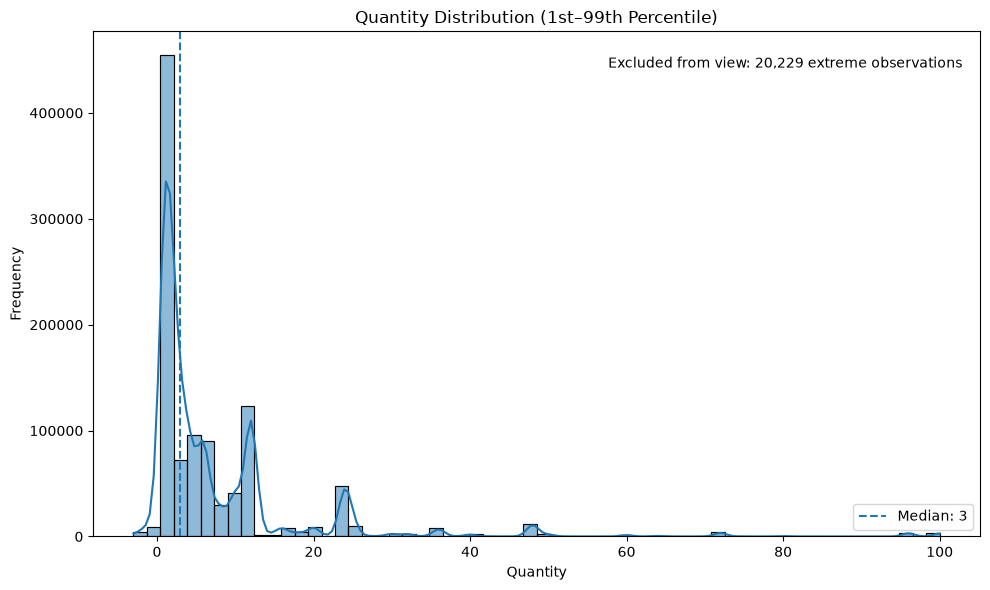

In [17]:
import importlib
import src.data.analysis as analysis
importlib.reload(analysis)
from src.data.analysis import (plot_quantity_distribution)
plot_quantity_distribution(df)

**[GO TO INDEX](#INDEX)**

## **``Step 8 Price Distribution:``**
The following visualization shows the distribution of unit prices in the raw
dataset and helps identify highly concentrated values and potential price
outliers.

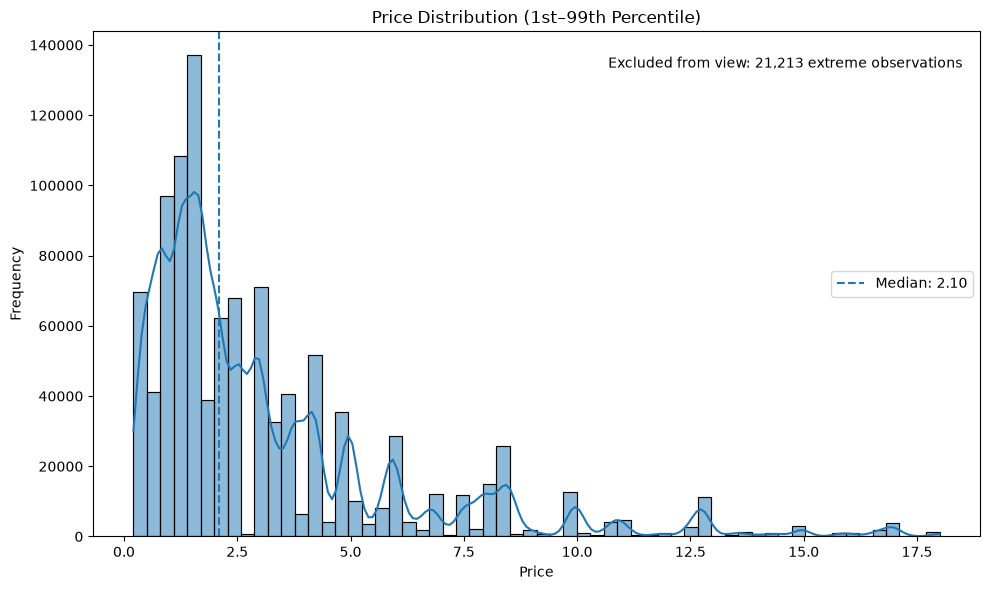

In [18]:
import importlib
import src.data.analysis as analysis
importlib.reload(analysis)
from src.data.analysis import (plot_price_distribution)
plot_price_distribution(df)

**[GO TO INDEX](#INDEX)**

## **``Step 9 Transaction Value Distribution:``**

The following visualization shows the distribution of transaction value
calculated from Quantity × Price.This helps identify highly skewed transactions and potential extreme
monetary observations before cleaning.

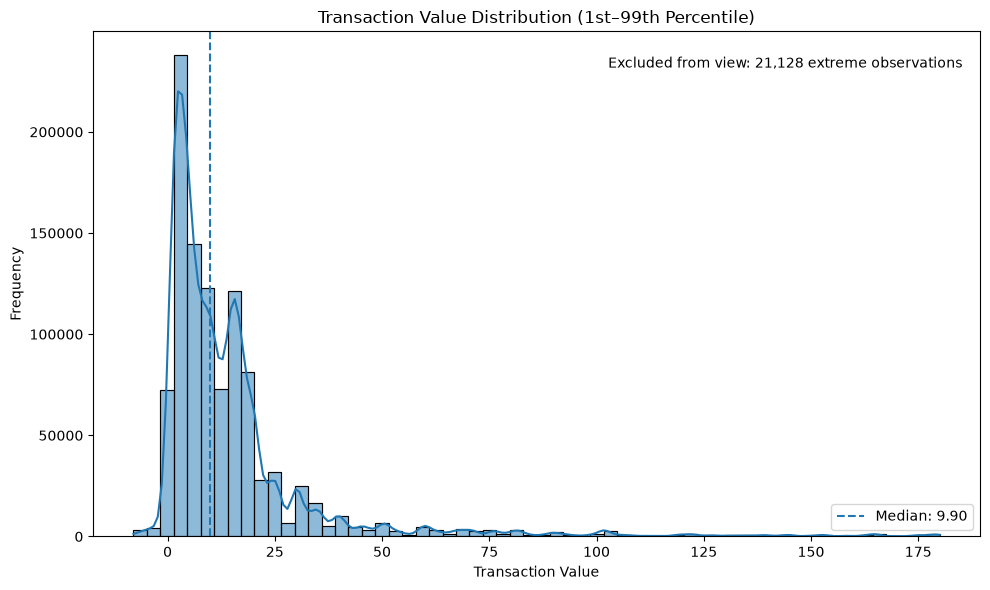

In [19]:
import importlib
import src.data.analysis as analysis
importlib.reload(analysis)
from src.data.analysis import (plot_transaction_value_distribution)
plot_transaction_value_distribution(df)

**[GO TO INDEX](#INDEX)**

## **``Step 10 Vantara Dataset cleaning - pipeline:``**

In [25]:
import importlib
import src.data.clean as clean
importlib.reload(clean)
from src.data.clean import clean_duplicates
from src.data.clean import standardize_descriptions
from src.data.clean import handle_quantity_and_price
from src.data.clean import summarize_quantity_price_treatment
from src.data.clean import handle_customer_id
from src.data.clean import validate_cleaned_data
from src.data.clean import clean_transaction_data

In [26]:
df_cleaned = clean_transaction_data(df)

E:\10. Internmo Projects\AIML_internmo_Project3_Vantara\2.AIML_Project3_Vantara_retail_solution\customer-behaviour-prediction\src\data\clean.py:565: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  r"|MISSING",


**[GO TO INDEX](#INDEX)**

## **``Step 11 Vantara Dataset Validation:``**

In [27]:
validation_results = validate_cleaned_data(df_cleaned)
validation_results

{'row_count': 1033036,
 'duplicate_rows': 0,
 'missing_customer_id': 0,
 'customer_id_flag_1': 235151,
 'customer_id_flag_0': 797885,
 'invalid_missing_customer_id_rows': 0,
 'invalid_available_customer_id_rows': 0,
 'invalid_customer_id_flag_values': 0,
 'missing_description': 0,
 'negative_quantity': 22496,
 'zero_quantity': 0,
 'zero_price': 6014,
 'negative_price': 5,
 'missing_invoice_date': 0,
 'missing_transaction_type': 0,
 'missing_quantity_treatment': 0,
 'missing_price_treatment': 0,
 'missing_sales_analysis_flag': 0,
 'missing_analytical_transaction_value': 0,
 'passed': True}

**[GO TO INDEX](#INDEX)**

## **``Step 12 Saving cleaned Dataframe:``**

In [34]:
import importlib
import src.data.ingest as ingest
importlib.reload(ingest)
from src.data.ingest import save_dataframe

In [35]:
cleaned_path = save_dataframe(df_cleaned,"data/interim","cleaned_transactions.csv")

Dataframe saved successfully: E:\10. Internmo Projects\AIML_internmo_Project3_Vantara\2.AIML_Project3_Vantara_retail_solution\customer-behaviour-prediction\data\interim\cleaned_transactions.csv


**[GO TO INDEX](#INDEX)**

#### **========================================================================================**

# **``EDA For Feature Engineering Churndataset:``**

## **``Step 1. Dataset loading:``**

In [6]:
import importlib
import src.data.ingest as ingest 
importlib.reload(ingest)

from src.data.ingest import save_dataframe
from src.data.ingest import load_config, load_dataframe

config = load_config()

churn_dataset = load_dataframe(
    config["data"]["processed_dir"],
    config["data"]["processed"]["churn_dataset"]["filename"],
)

Dataframe loaded successfully: E:\10. Internmo Projects\AIML_internmo_Project3_Vantara\2.AIML_Project3_Vantara_retail_solution\customer-behaviour-prediction\data\processed\customer_churn_dataset.csv
Shape: (5281, 35)


**[GO TO INDEX](#INDEX)**

## **``Step 2. Churn Target Distribution:``**

In [11]:
import importlib
import src.data.analysis as analysis
importlib.reload(analysis)
from src.data.analysis import analyze_churn_distribution

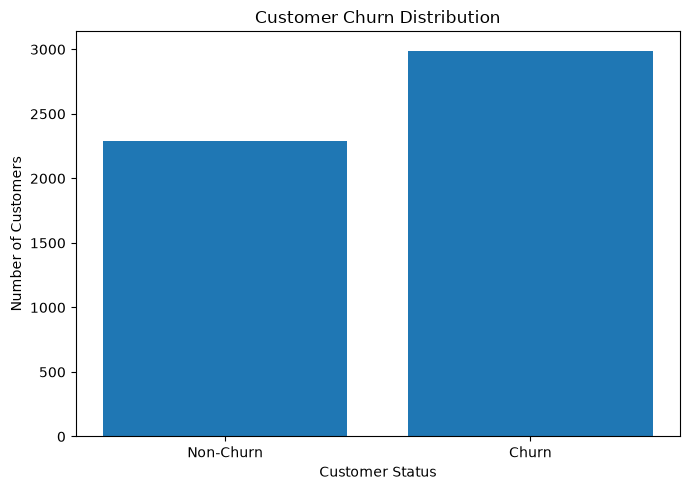

,Churn,Customer_Status,Customer_Count,Percentage
0,0,Non-Churn,2291,43.38
1,1,Churn,2990,56.62


In [12]:
churn_distribution = analyze_churn_distribution(churn_dataset)
churn_distribution

**[GO TO INDEX](#INDEX)**

## **``Step 3. analyze_numerical_features:``**

In [14]:
import importlib
import src.data.analysis as analysis
importlib.reload(analysis)
from src.data.analysis import analyze_numerical_features

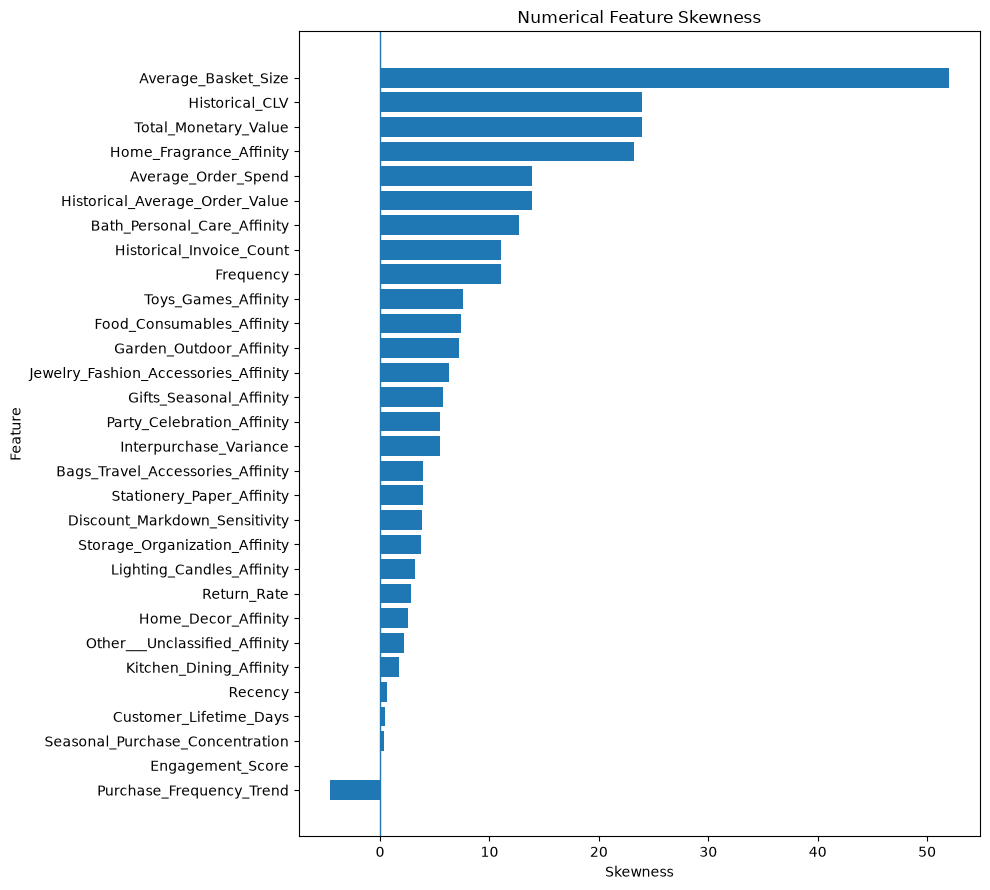

,count,mean,std,min,25%,50%,75%,max,skewness
Recency,5281.0,207.8412,175.0531,0.8700,49.9600,164.0700,326.8900,648.1200,0.6647
Frequency,5281.0,5.7455,11.4645,1.0000,1.0000,3.0000,6.0000,309.0000,11.0709
Total_Monetary_Value,5281.0,2623.2479,12182.0227,2.9000,318.2400,782.9500,2077.0700,456780.4900,23.9763
Average_Order_Spend,5281.0,368.0750,531.6511,2.9000,174.6400,276.7100,409.5700,14844.7700,13.8851
Historical_CLV,5281.0,2623.2479,12182.0227,2.9000,318.2400,782.9500,2077.0700,456780.4900,23.9763
Customer_Lifetime_Days,5281.0,224.4616,218.9590,0.0000,0.0000,170.7400,417.9600,646.1500,0.4568
Historical_Average_Order_Value,5281.0,368.0750,531.6511,2.9000,174.6400,276.7100,409.5700,14844.7700,13.8851
Historical_Invoice_Count,5281.0,5.7455,11.4645,1.0000,1.0000,3.0000,6.0000,309.0000,11.0709
Average_Basket_Size,5281.0,240.5181,1397.6462,1.0000,87.0000,148.0000,251.0000,87167.0000,52.0023
Purchase_Frequency_Trend,5281.0,-0.0316,0.0770,-1.2000,-0.0382,-0.0130,0.0000,1.0000,-4.6104


In [15]:
numerical_statistics = analyze_numerical_features(churn_dataset)
numerical_statistics

**[GO TO INDEX](#INDEX)**

## **``Step 4. Feature Distribution & Outlier Analysis:``**

In [26]:
import importlib
import src.data.analysis as analysis
importlib.reload(analysis)
from src.data.analysis import analyze_feature_distributions
from src.data.analysis import analyze_feature_outliers

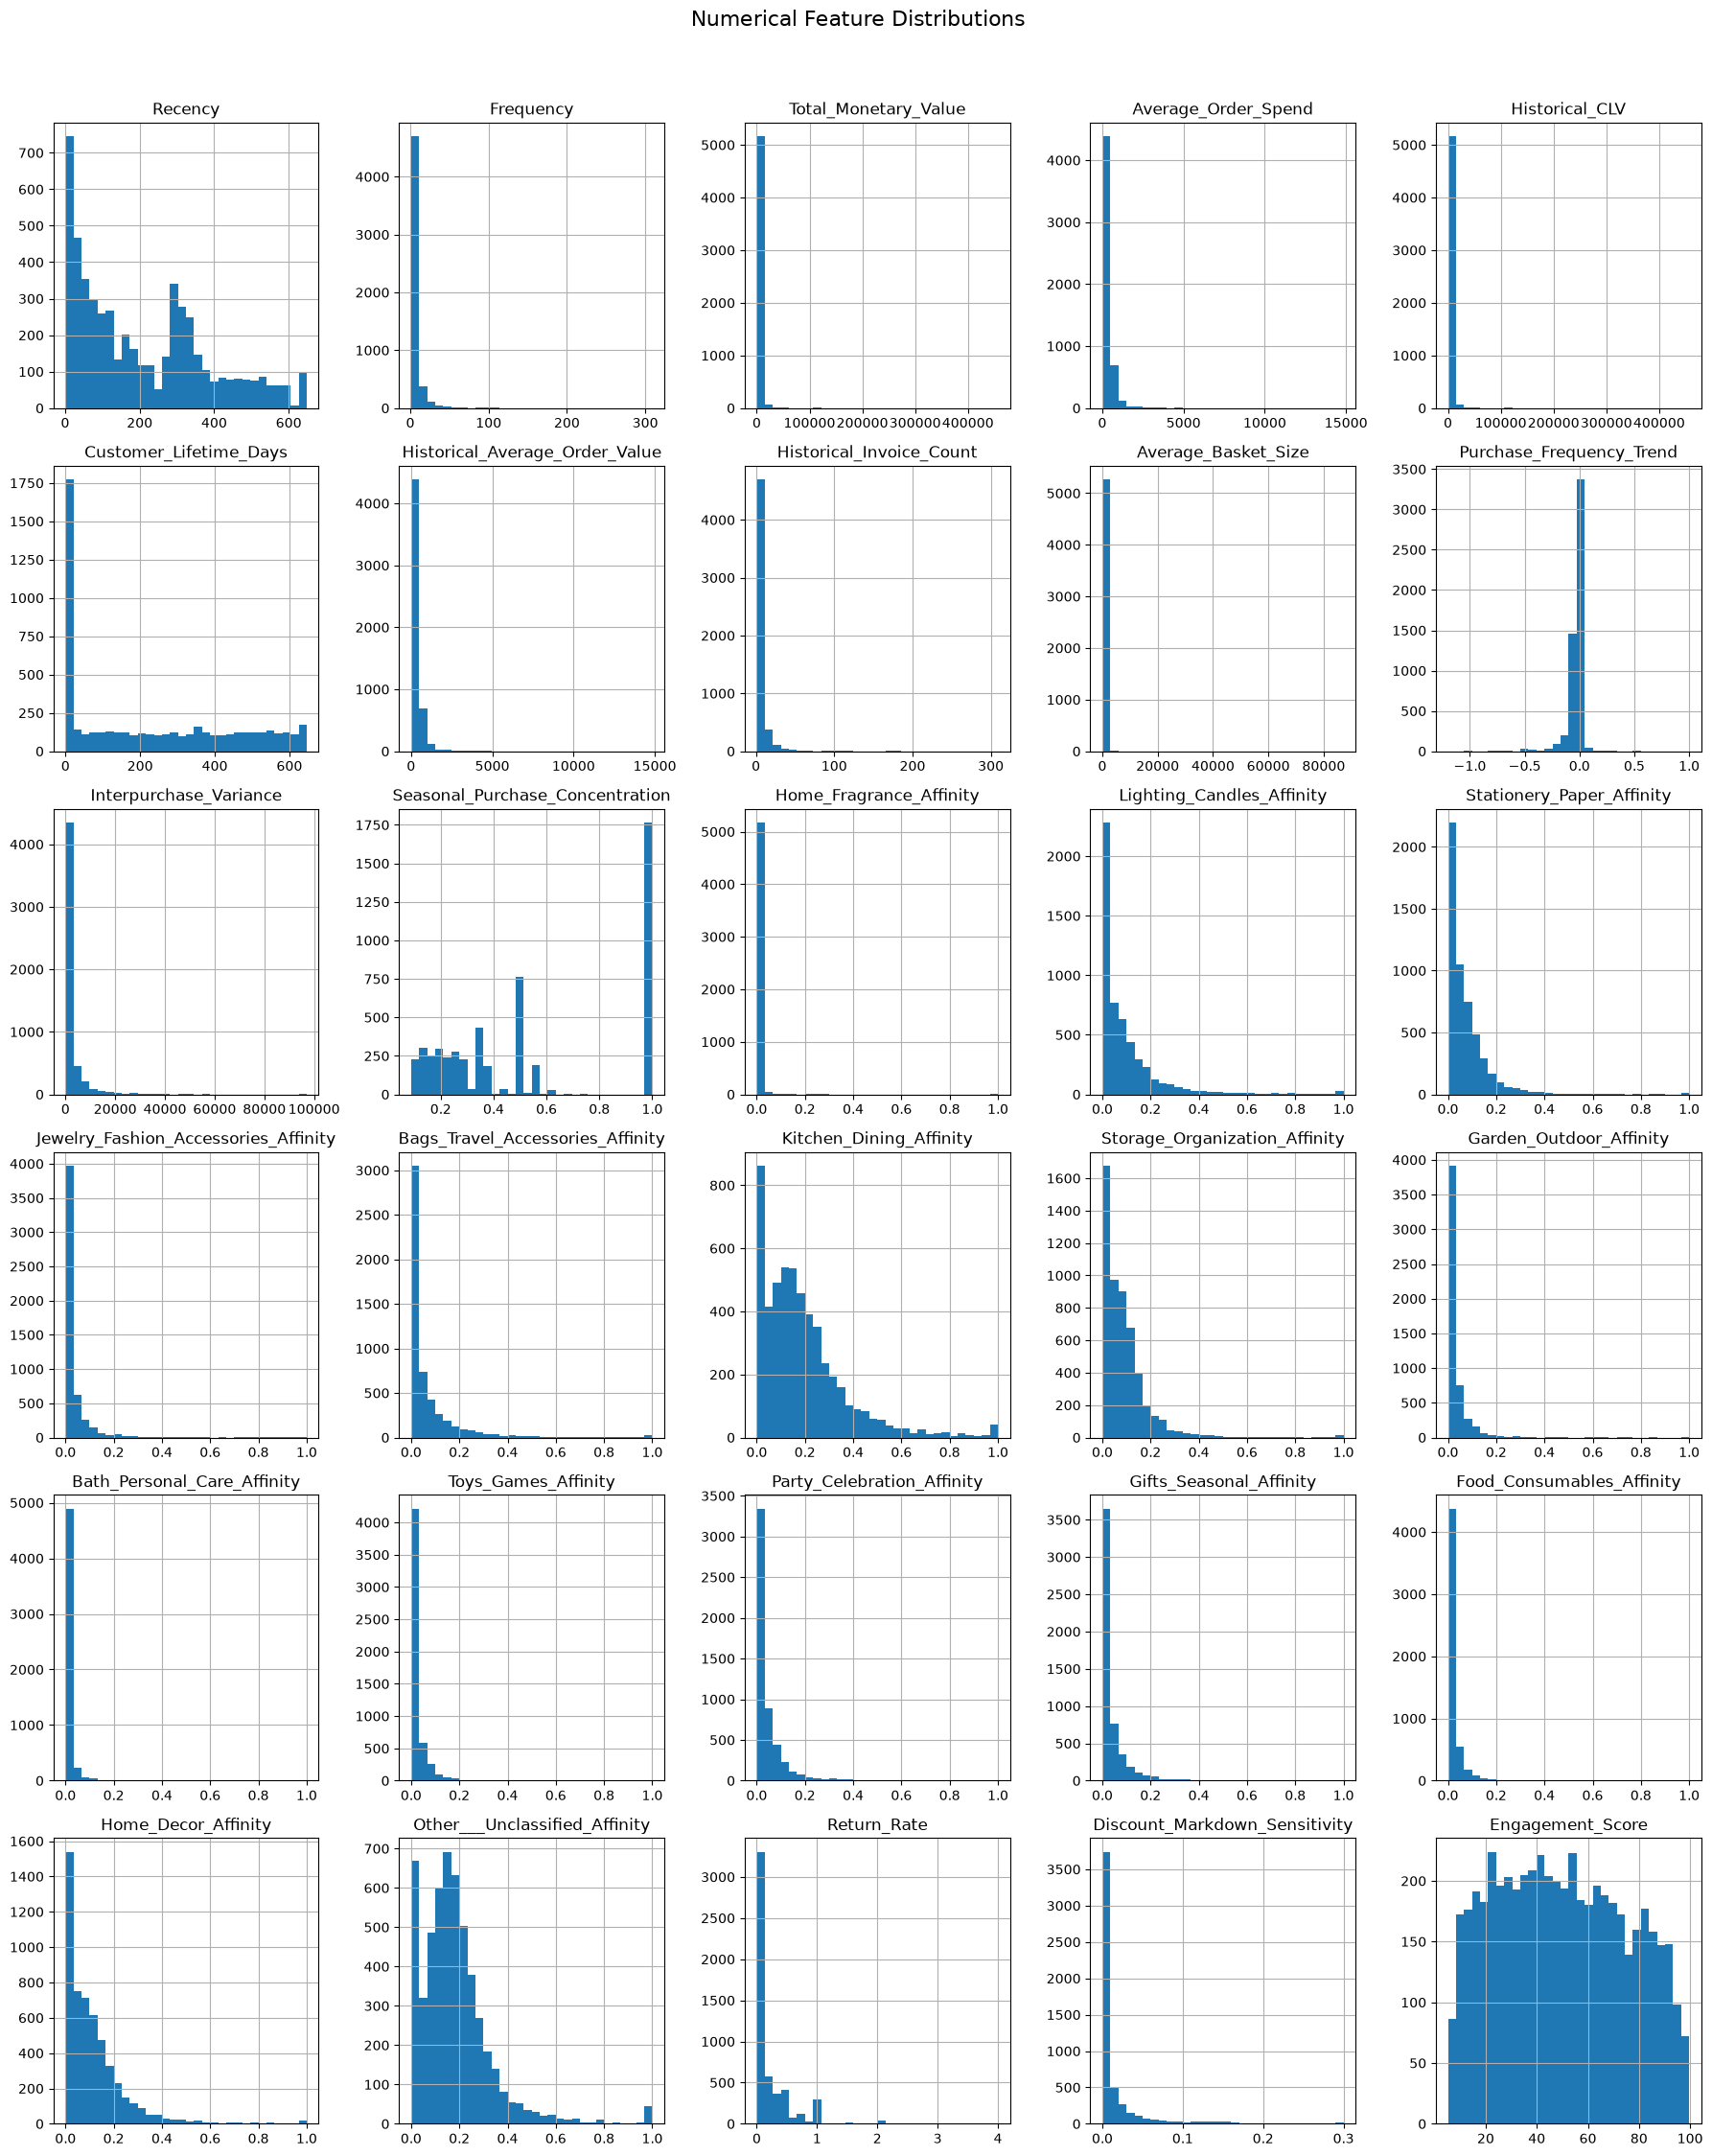

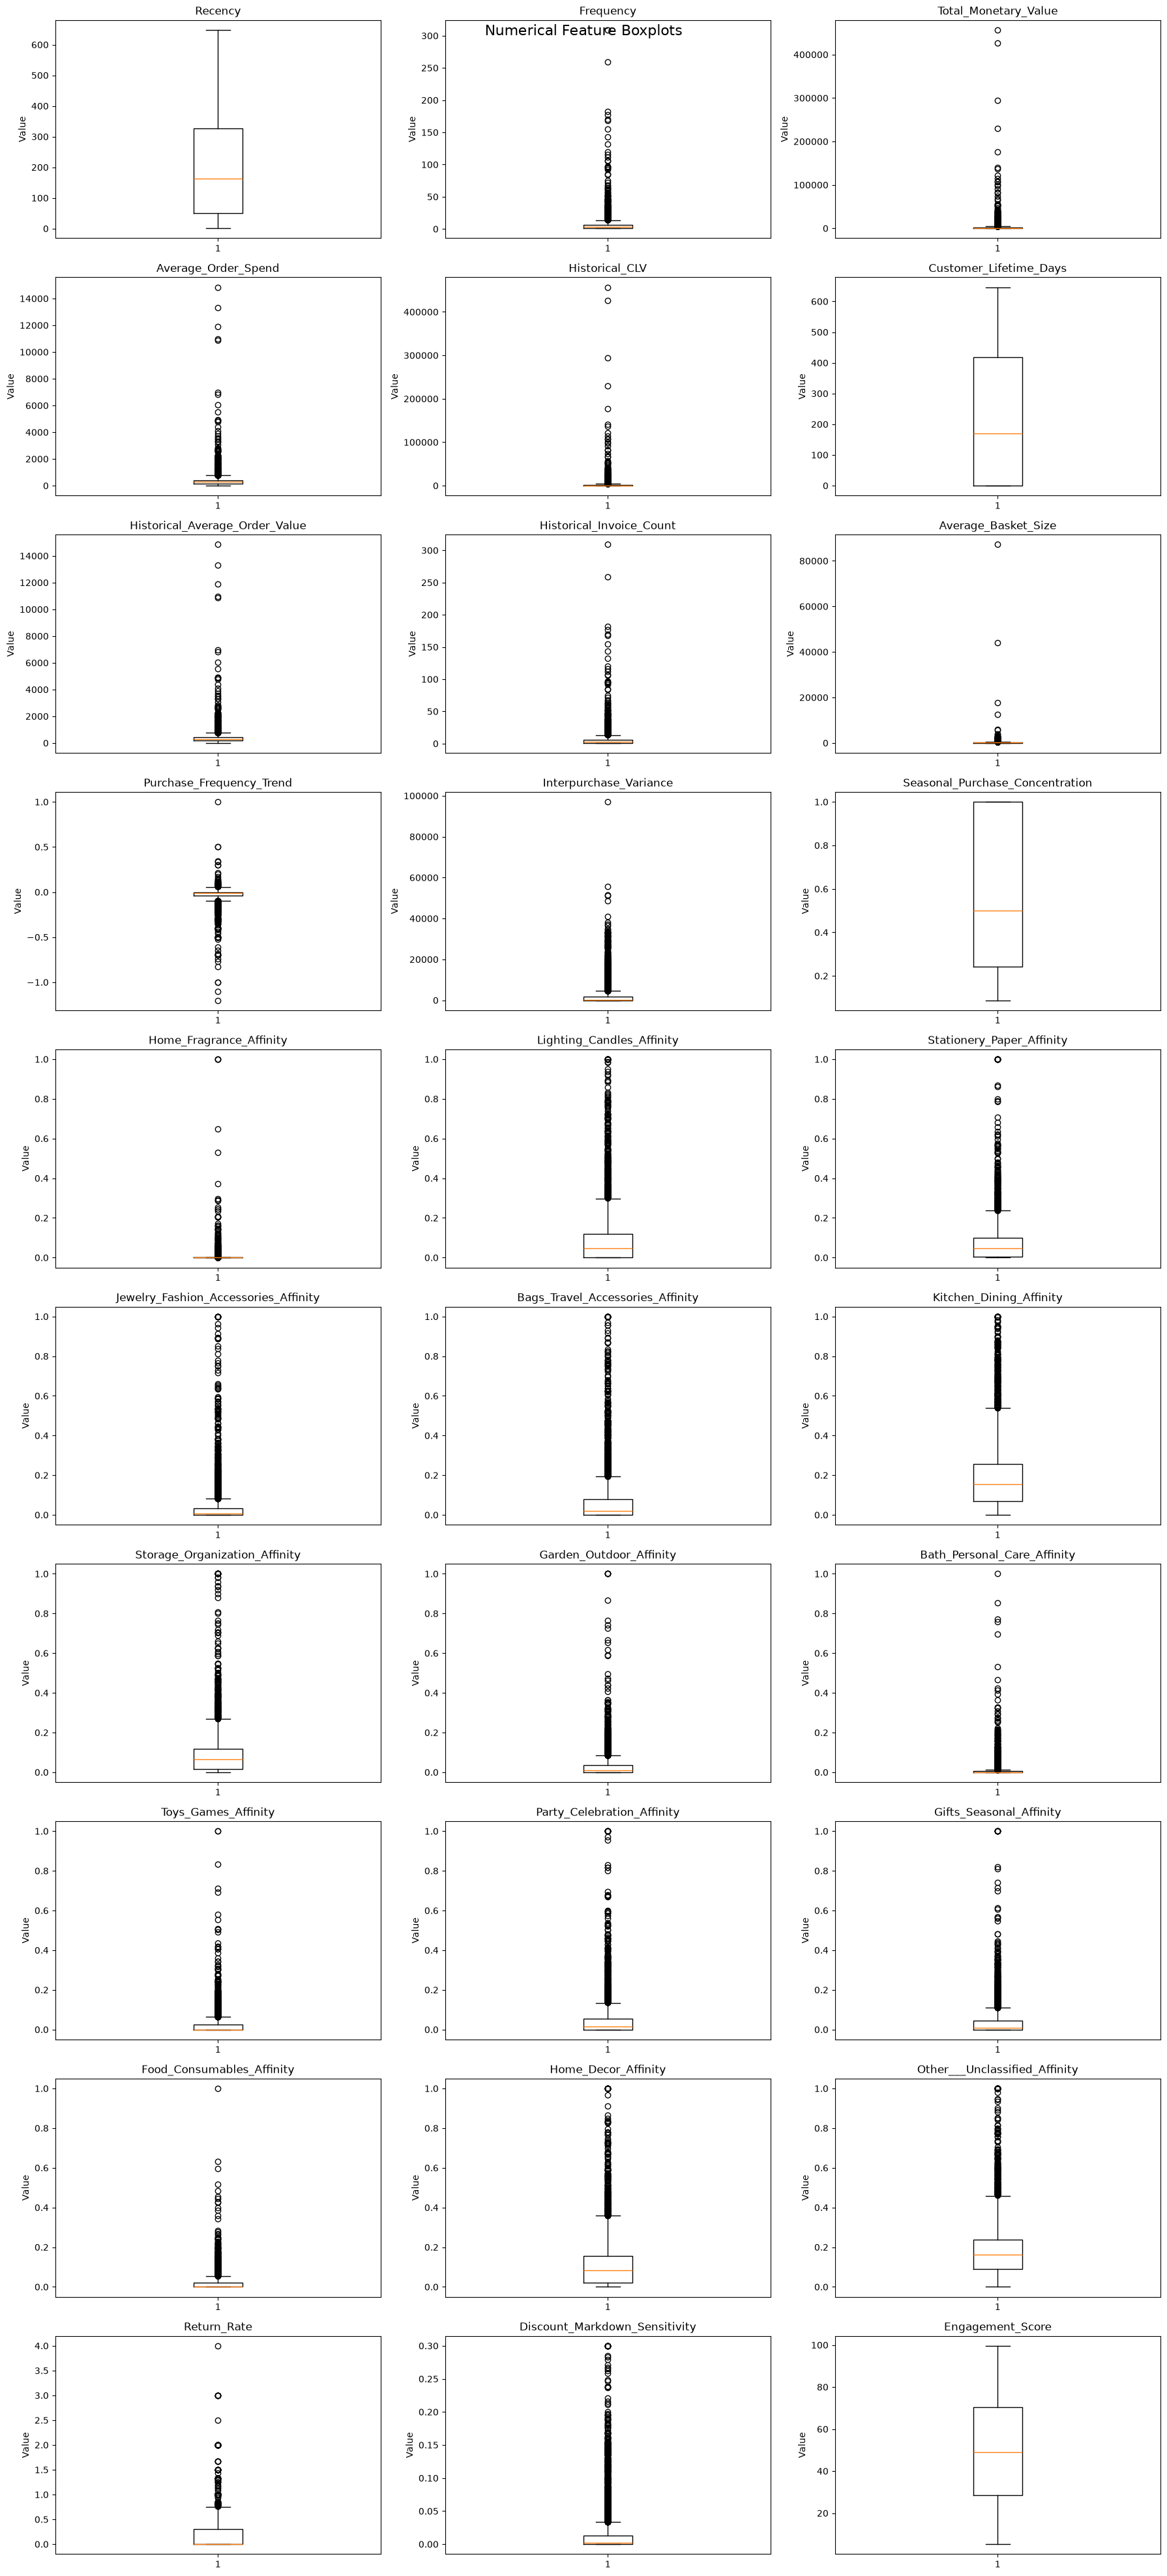

In [23]:
analyze_feature_distributions(churn_dataset)

## **``Outlier``**

In [27]:
outlier_summary = analyze_feature_outliers(churn_dataset)
outlier_summary

,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
Bath_Personal_Care_Affinity,0.0000,0.0054,0.0054,-0.0081,0.0134,832,15.7546
Home_Fragrance_Affinity,0.0000,0.0000,0.0000,0.0000,0.0000,719,13.6148
Discount_Markdown_Sensitivity,0.0000,0.0134,0.0134,-0.0201,0.0335,701,13.2740
Interpurchase_Variance,0.0000,1839.1590,1839.1590,-2758.7384,4597.8974,678,12.8385
Historical_CLV,318.2400,2077.0700,1758.8300,-2320.0050,4715.3150,564,10.6798
Total_Monetary_Value,318.2400,2077.0700,1758.8300,-2320.0050,4715.3150,564,10.6798
Jewelry_Fashion_Accessories_Affinity,0.0000,0.0328,0.0328,-0.0492,0.0820,548,10.3768
Toys_Games_Affinity,0.0000,0.0256,0.0256,-0.0383,0.0639,517,9.7898
Bags_Travel_Accessories_Affinity,0.0000,0.0781,0.0781,-0.1171,0.1951,504,9.5436
Food_Consumables_Affinity,0.0000,0.0222,0.0222,-0.0332,0.0554,484,9.1649


**[GO TO INDEX](#INDEX)**

## **``Step 5. Compare Features by Churn:``**

In [31]:
import importlib
import src.data.analysis as analysis
importlib.reload(analysis)
from src.data.analysis import analyze_features_by_churn

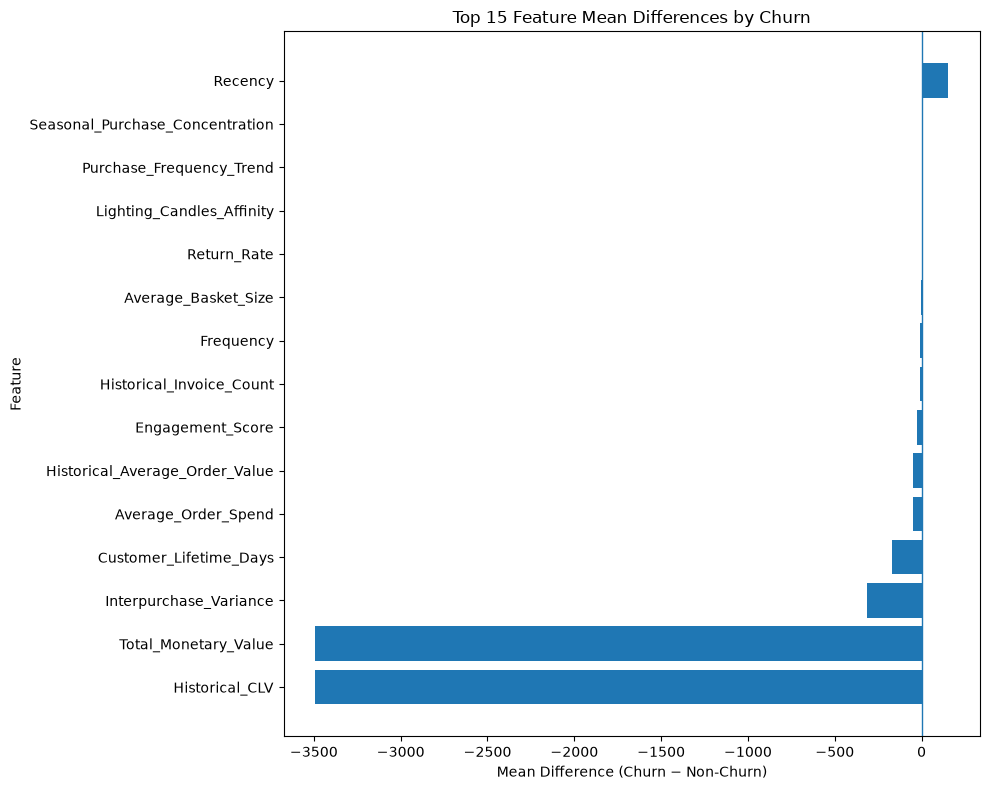

,Mean_Non_Churn,Mean_Churn,Median_Non_Churn,Median_Churn,Mean_Difference,Median_Difference,Absolute_Mean_Difference
Historical_CLV,4600.2486,1108.4291,1606.4200,483.8200,-3491.8195,-1122.6000,3491.8195
Total_Monetary_Value,4600.2486,1108.4291,1606.4200,483.8200,-3491.8195,-1122.6000,3491.8195
Interpurchase_Variance,2177.0232,1862.2021,641.6777,0.0000,-314.8210,-641.6777,314.8210
Customer_Lifetime_Days,321.0578,150.4476,346.0000,47.7200,-170.6102,-298.2800,170.6102
Recency,120.5515,274.7244,67.0300,287.9700,154.1729,220.9400,154.1729
Average_Order_Spend,395.2115,347.2825,306.7000,246.5200,-47.9291,-60.1800,47.9291
Historical_Average_Order_Value,395.2115,347.2824,306.7000,246.5200,-47.9291,-60.1800,47.9291
Engagement_Score,64.2338,39.0993,67.0864,36.5224,-25.1345,-30.5640,25.1345
Historical_Invoice_Count,9.2584,3.0538,5.0000,2.0000,-6.2046,-3.0000,6.2046
Frequency,9.2584,3.0538,5.0000,2.0000,-6.2046,-3.0000,6.2046


In [32]:
churn_feature_comparison = analyze_features_by_churn(churn_dataset)
churn_feature_comparison

**[GO TO INDEX](#INDEX)**

## **``Step 6. Correlation with Churn:``**

In [34]:
import importlib
import src.data.analysis as analysis
importlib.reload(analysis)
from src.data.analysis import analyze_feature_churn_correlation

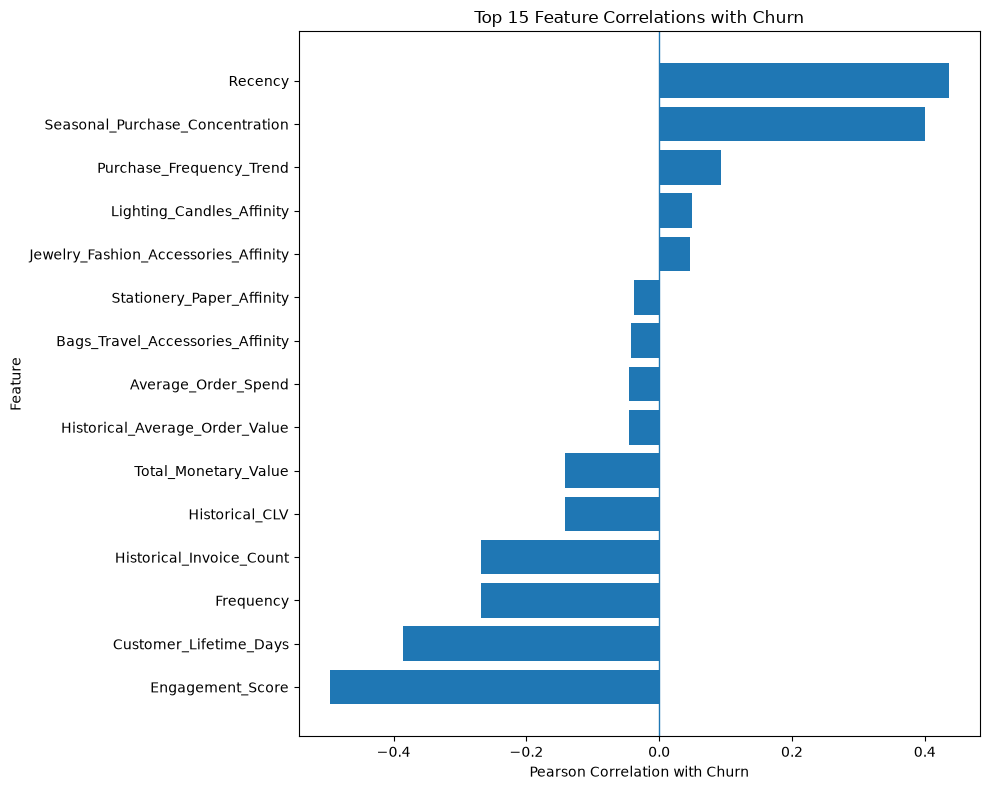

,Correlation_With_Churn,Absolute_Correlation,Relationship
Engagement_Score,-0.4963,0.4963,Negative
Recency,0.4365,0.4365,Positive
Seasonal_Purchase_Concentration,0.4005,0.4005,Positive
Customer_Lifetime_Days,-0.3862,0.3862,Negative
Historical_Invoice_Count,-0.2682,0.2682,Negative
Frequency,-0.2682,0.2682,Negative
Historical_CLV,-0.1421,0.1421,Negative
Total_Monetary_Value,-0.1421,0.1421,Negative
Purchase_Frequency_Trend,0.0930,0.0930,Positive
Lighting_Candles_Affinity,0.0495,0.0495,Positive


In [35]:
churn_correlation = analyze_feature_churn_correlation(churn_dataset)
churn_correlation 

**[GO TO INDEX](#INDEX)**

## **``Step 7. Feature to Feature Correlation:``**

In [36]:
import importlib
import src.data.analysis as analysis
importlib.reload(analysis)
from src.data.analysis import analyze_feature_correlations

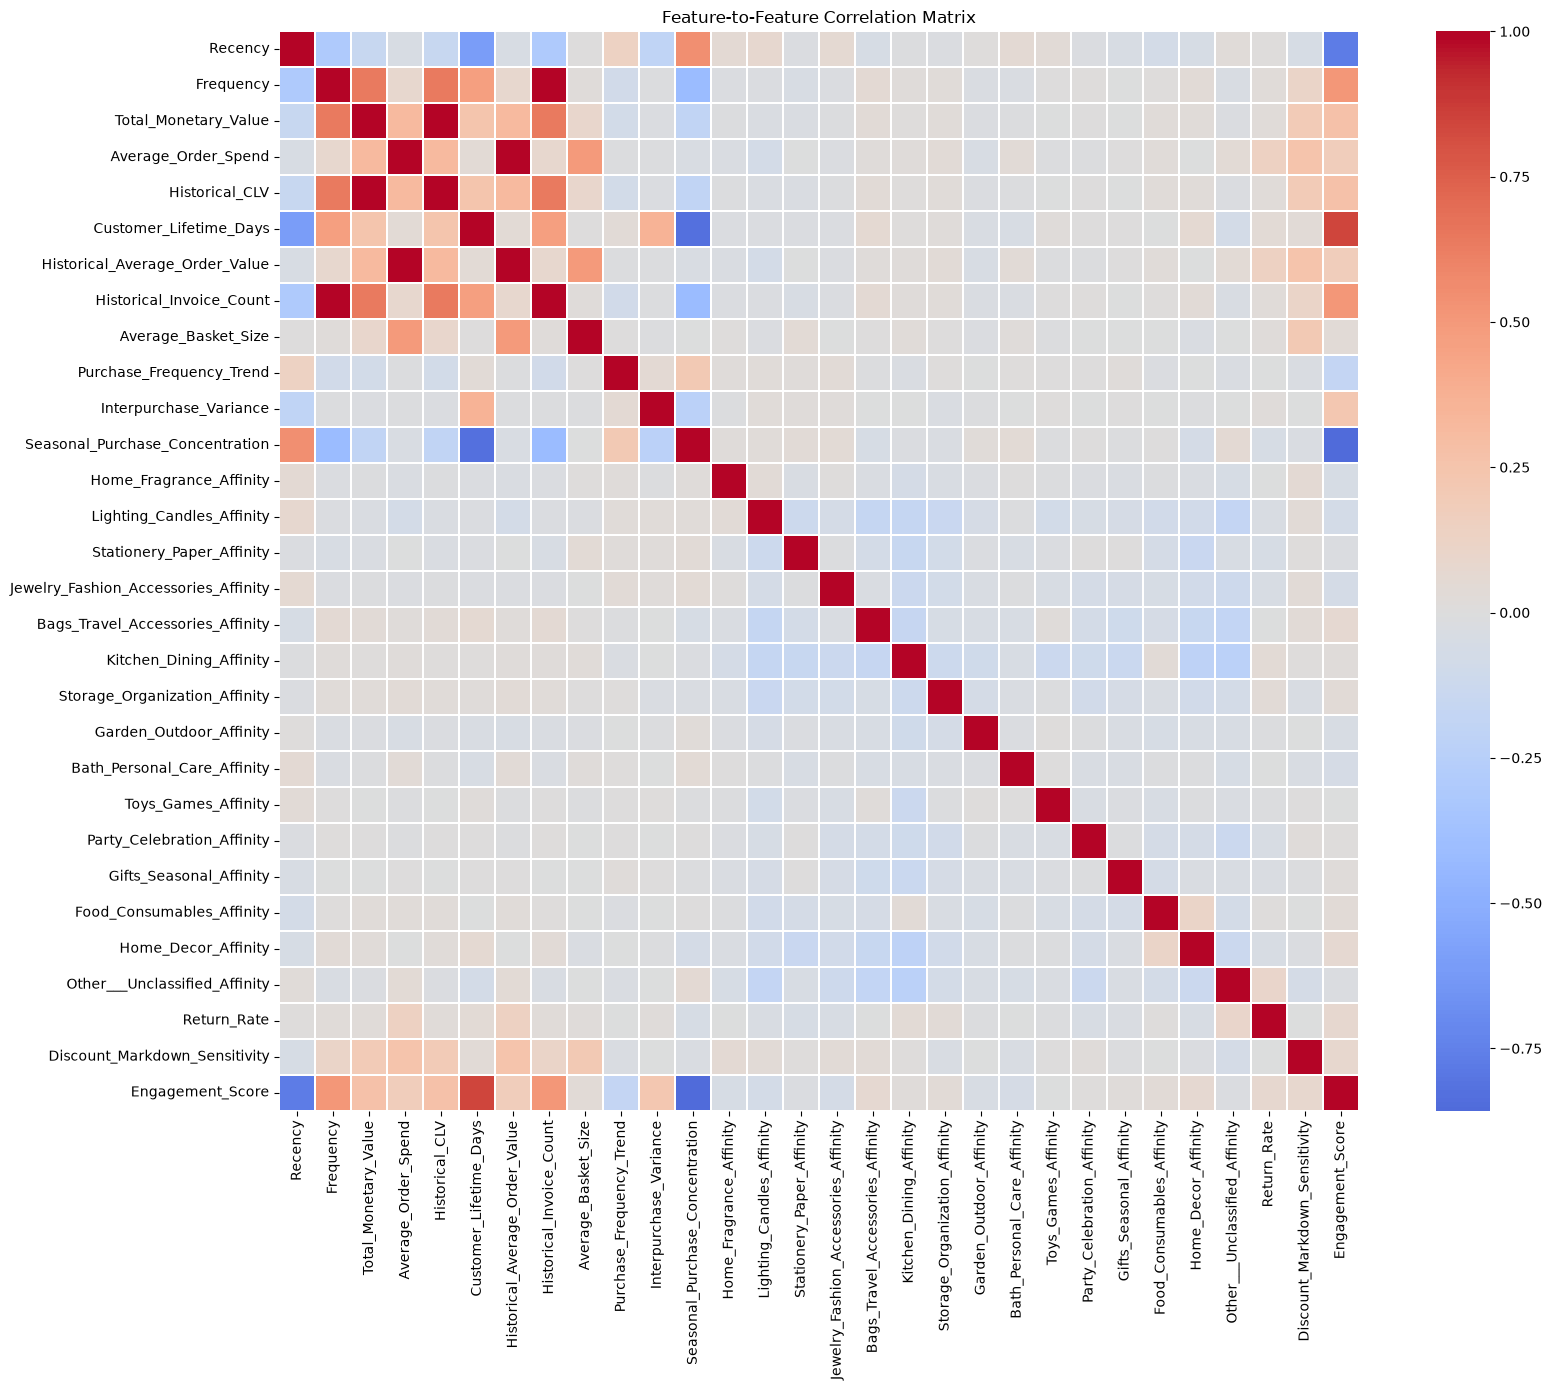

In [37]:
feature_correlation_matrix, high_correlation_pairs = (analyze_feature_correlations(churn_dataset,threshold=0.80,))

In [39]:
feature_correlation_matrix

,Recency,Frequency,Total_Monetary_Value,Average_Order_Spend,Historical_CLV,Customer_Lifetime_Days,Historical_Average_Order_Value,Historical_Invoice_Count,Average_Basket_Size,Purchase_Frequency_Trend,...,Bath_Personal_Care_Affinity,Toys_Games_Affinity,Party_Celebration_Affinity,Gifts_Seasonal_Affinity,Food_Consumables_Affinity,Home_Decor_Affinity,Other___Unclassified_Affinity,Return_Rate,Discount_Markdown_Sensitivity,Engagement_Score
Recency,1.0000,-0.3002,-0.1511,-0.0413,-0.1511,-0.6001,-0.0413,-0.3002,0.0058,0.1392,...,0.0566,0.0370,-0.0163,-0.0395,-0.0721,-0.0509,0.0219,0.0091,-0.0478,-0.7769
Frequency,-0.3002,1.0000,0.6409,0.0834,0.6409,0.4757,0.0834,1.0000,0.0141,-0.0912,...,-0.0244,-0.0006,0.0119,-0.0085,0.0109,0.0344,-0.0365,0.0243,0.1079,0.5083
Total_Monetary_Value,-0.1511,0.6409,1.0000,0.3144,1.0000,0.2385,0.3144,0.6409,0.0876,-0.0840,...,-0.0106,-0.0056,-0.0010,-0.0060,0.0207,0.0240,-0.0202,0.0254,0.1985,0.2704
Average_Order_Spend,-0.0413,0.0834,0.3144,1.0000,0.3144,0.0468,1.0000,0.0834,0.4943,-0.0090,...,0.0296,-0.0104,-0.0087,0.0026,0.0230,-0.0081,0.0467,0.1474,0.2550,0.1747
Historical_CLV,-0.1511,0.6409,1.0000,0.3144,1.0000,0.2385,0.3144,0.6409,0.0876,-0.0840,...,-0.0106,-0.0056,-0.0010,-0.0060,0.0207,0.0240,-0.0202,0.0254,0.1985,0.2704
Customer_Lifetime_Days,-0.6001,0.4757,0.2385,0.0468,0.2385,1.0000,0.0468,0.4757,0.0016,0.0414,...,-0.0439,0.0157,0.0047,0.0024,-0.0032,0.0620,-0.0694,0.0464,0.0376,0.8467
Historical_Average_Order_Value,-0.0413,0.0834,0.3144,1.0000,0.3144,0.0468,1.0000,0.0834,0.4943,-0.0090,...,0.0296,-0.0104,-0.0087,0.0026,0.0230,-0.0081,0.0467,0.1474,0.2550,0.1747
Historical_Invoice_Count,-0.3002,1.0000,0.6409,0.0834,0.6409,0.4757,0.0834,1.0000,0.0141,-0.0912,...,-0.0244,-0.0006,0.0119,-0.0085,0.0109,0.0344,-0.0365,0.0243,0.1079,0.5083
Average_Basket_Size,0.0058,0.0141,0.0876,0.4943,0.0876,0.0016,0.4943,0.0141,1.0000,0.0010,...,0.0150,-0.0089,-0.0044,-0.0034,-0.0062,-0.0241,-0.0083,0.0203,0.2098,0.0399
Purchase_Frequency_Trend,0.1392,-0.0912,-0.0840,-0.0090,-0.0840,0.0414,-0.0090,-0.0912,0.0010,1.0000,...,0.0115,0.0051,0.0042,0.0171,-0.0206,-0.0036,-0.0297,-0.0027,-0.0300,-0.1731


In [38]:
high_correlation_pairs

,Feature_1,Feature_2,Correlation,Absolute_Correlation
0,Frequency,Historical_Invoice_Count,1.0000,1.0000
1,Total_Monetary_Value,Historical_CLV,1.0000,1.0000
2,Average_Order_Spend,Historical_Average_Order_Value,1.0000,1.0000
3,Seasonal_Purchase_Concentration,Engagement_Score,-0.8574,0.8574
4,Customer_Lifetime_Days,Engagement_Score,0.8467,0.8467
5,Customer_Lifetime_Days,Seasonal_Purchase_Concentration,-0.8274,0.8274


**[GO TO INDEX](#INDEX)**

## **``Step 8. VIF Analysis:``**

In [42]:
import importlib
import src.data.analysis as analysis
importlib.reload(analysis)
from src.data.analysis import analyze_vif

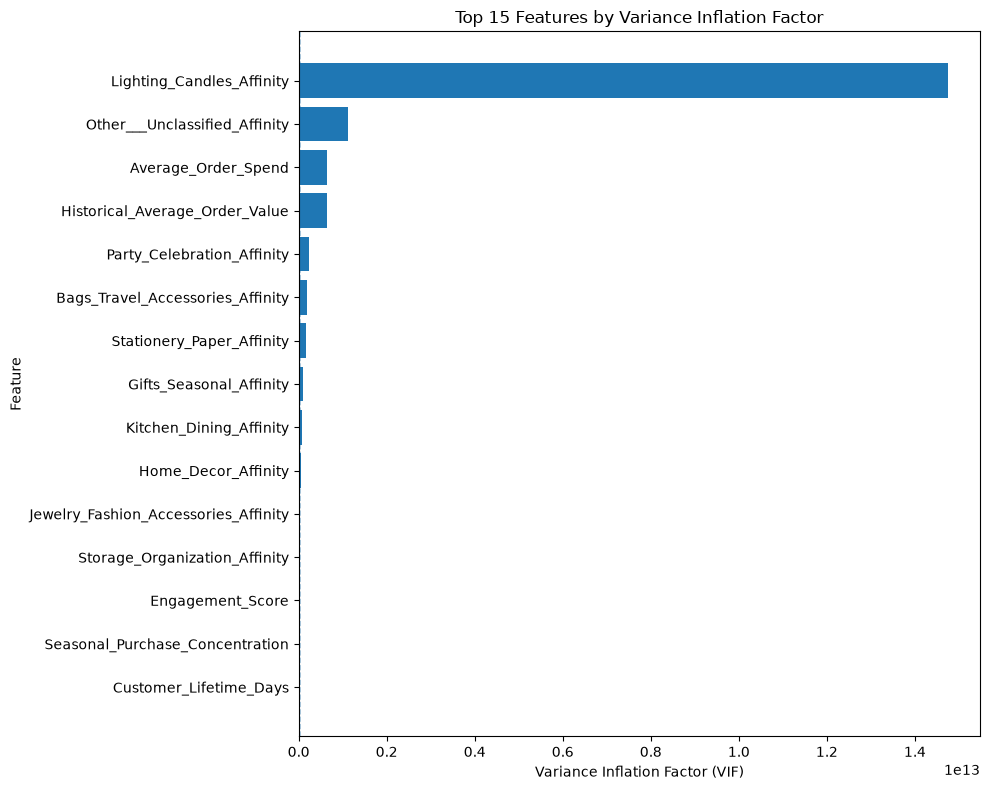

,Feature,VIF,VIF_Level
0,Lighting_Candles_Affinity,1.474173e+13,High
1,Other___Unclassified_Affinity,1.117935e+12,High
2,Historical_Average_Order_Value,6.514211e+11,High
3,Average_Order_Spend,6.514211e+11,High
4,Party_Celebration_Affinity,2.401023e+11,High
5,Bags_Travel_Accessories_Affinity,2.000711e+11,High
6,Stationery_Paper_Affinity,1.569089e+11,High
7,Gifts_Seasonal_Affinity,9.318531e+10,High
8,Kitchen_Dining_Affinity,8.370925e+10,High
9,Home_Decor_Affinity,4.416246e+10,High


In [43]:
vif_results = analyze_vif(churn_dataset)
vif_results

**[GO TO INDEX](#INDEX)**

## **``Step 9. Important Features & Initial Churn Hypotheses:``**

In [52]:
import importlib
import src.data.analysis as analysis
importlib.reload(analysis)
from src.data.analysis import analyze_churn_feature_importance

In [53]:
churn_feature_importance = analyze_churn_feature_importance(churn_dataset,churn_correlation,churn_feature_comparison,vif_results,)
churn_feature_importance 

,Feature,Correlation_With_Churn,Absolute_Correlation,Mean_Difference,Absolute_Mean_Difference,VIF,VIF_Level,Priority
0,Engagement_Score,-0.4963,0.4963,-25.1345,25.1345,1.282500e+01,High,1.0
1,Recency,0.4365,0.4365,154.1729,154.1729,3.455900e+00,Low,2.0
2,Seasonal_Purchase_Concentration,0.4005,0.4005,0.2789,0.2789,6.097000e+00,Moderate,3.0
3,Customer_Lifetime_Days,-0.3862,0.3862,-170.6102,170.6102,6.095800e+00,Moderate,4.0
4,Historical_Invoice_Count,-0.2682,0.2682,-6.2046,6.2046,NaN,Infinite / Undefined,5.0
5,Frequency,-0.2682,0.2682,-6.2046,6.2046,NaN,Infinite / Undefined,5.0
6,Historical_CLV,-0.1421,0.1421,-3491.8195,3491.8195,NaN,Infinite / Undefined,7.0
7,Total_Monetary_Value,-0.1421,0.1421,-3491.8195,3491.8195,NaN,Infinite / Undefined,7.0
8,Purchase_Frequency_Trend,0.0930,0.0930,0.0144,0.0144,1.327700e+00,Low,9.0
9,Lighting_Candles_Affinity,0.0495,0.0495,0.0139,0.0139,1.474173e+13,High,10.0


**[GO TO INDEX](#INDEX)**

#### **====================================== END OF EDA ========================================**